# 03b · Significant topic routes between communities (backbone prototype)

RQ1 says *how often* a topic crosses community boundaries. This notebook asks **along which routes**: when
content of topic *t* leaves community X, which communities Y does it go to **more than expected**?
Settings fixed before running: `docs/DECISIONS.md` **D21**.

**How it works**
1. For each topic, build a small network whose nodes are communities (notebook 02). Edge X → Y = number
   of English–English text forwards of that topic written in X and reposted in Y (X ≠ Y: crossing
   forwards only).
2. Apply the **noise-corrected backbone** (Coscia & Neffke 2017) to that network. Expected X → Y =
   (topic-*t* forwards X sends to other communities) × (topic-*t* forwards Y receives from other
   communities) / (all topic-*t* crossing forwards). A route is **significant** if its lift over that
   expectation is above zero by more than 1.64 standard deviations.
3. The same over all topics gives the reference: the routes crossing content uses in general.

Community conspiracy level (display only): **high** ≥ 30% of channels in the conspiracy list, **low**
< 10%, **middle** otherwise. Edge direction: content flow, `src -> dest`.

**Caveat:** topics here are the source channel's LDA topic (interim). Routes partly reflect channel types;
the real result needs message-level topics (notebook 04).

In [1]:
import json, random, sys
from pathlib import Path

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("src").resolve()))
from tgperm import config as cfg, data, plots, backbone

plots.use_style()
OUT = cfg.RESULTS / "03b"   # this notebook's tables and figures
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 70, "display.width", 220)

con = data.connect()
channels = data.channel_table(con).set_index("channel_id")
community = pd.read_parquet(cfg.DERIVED / "communities.parquet").set_index("channel_id").community
fw = pd.read_parquet(data.build_en_text_windows(con))
fw = fw.assign(topic=fw.src_id.map(channels.ch_topic),
               src_c=fw.src_id.map(community).to_numpy(), dst_c=fw.dest_id.map(community).to_numpy())
cross = fw[fw.src_c != fw.dst_c]
print(f"crossing English–English text forwards: {cross.n_text.sum():,} of {fw.n_text.sum():,}, "
      f"between {cross.src_c.nunique()} source and {cross.dst_c.nunique()} destination communities")

# Community descriptors: conspiracy level (all channels), main channel topic and size (English channels)
mem = channels.join(community, how="inner")
comm = mem.groupby("community").agg(channels=("conspiracy", "size"), conspiracy_share=("conspiracy", "mean"))
en = mem[mem.language == "en"]
comm["english_channels"] = en.groupby("community").size().reindex(comm.index, fill_value=0)
comm["main_topic"] = en.groupby("community").ch_topic.agg(lambda s: s.value_counts().index[0])
comm["level"] = np.select([comm.conspiracy_share >= 0.30, comm.conspiracy_share < 0.10], ["high", "low"], "middle")
comm["label"] = [f"C{c} · {t} · {p:.0%} consp." if isinstance(t, str) else f"C{c} · {p:.0%} consp."
                 for c, t, p in zip(comm.index, comm.main_topic, comm.conspiracy_share)]
print(comm[comm.english_channels >= 30].level.value_counts().to_string())

crossing English–English text forwards: 386,975 of 7,731,006, between 58 source and 50 destination communities
level
low       16
high       5
middle     1


## 1 · Routes per topic

`routes used` = community pairs with at least one crossing forward of the topic; `on significant routes`
= share of the topic's crossing forwards that travel on significant routes; `high → low` = share of the
topic's crossing forwards going from a high-conspiracy to a low-conspiracy community, in total and on
significant routes.

In [2]:
def routes_for(d):
    r = d.groupby(["src_c", "dst_c"], as_index=False).n_text.sum().rename(
        columns={"src_c": "src_id", "dst_c": "dest_id", "n_text": "weight"})
    r = pd.concat([r, backbone.noise_corrected(r)], axis=1)
    r["significant"] = backbone.keep_nc(r)
    ni = r.groupby("src_id").weight.transform("sum"); nj = r.groupby("dest_id").weight.transform("sum")
    r["expected"] = ni * nj / r.weight.sum()
    r["lift"] = r.weight / r.expected
    r["share_of_topic_crossing"] = r.weight / r.weight.sum()
    r["src_level"] = r.src_id.map(comm.level).to_numpy(); r["dst_level"] = r.dest_id.map(comm.level).to_numpy()
    return r

topics = sorted(cross.topic.unique())
R = {"all topics": routes_for(cross)} | {t: routes_for(cross[cross.topic == t]) for t in topics}
allr = pd.concat(R, names=["topic"]).reset_index(level=0)

def summary(r):
    hl = (r.src_level == "high") & (r.dst_level == "low")
    return {"crossing forwards": int(r.weight.sum()), "routes used": len(r), "significant routes": int(r.significant.sum()),
            "on significant routes": r.weight[r.significant].sum() / r.weight.sum(),
            "high → low (all routes)": r.weight[hl].sum() / r.weight.sum(),
            "high → low (significant routes)": r.weight[hl & r.significant].sum() / r.weight.sum()}

summ = pd.DataFrame({t: summary(r) for t, r in R.items()}).T.sort_values("crossing forwards", ascending=False)
summ.style.format({"crossing forwards": "{:,.0f}", "routes used": "{:,.0f}", "significant routes": "{:,.0f}",
                   "on significant routes": "{:.0%}", "high → low (all routes)": "{:.1%}",
                   "high → low (significant routes)": "{:.1%}"})

,crossing forwards,routes used,significant routes,on significant routes,high → low (all routes),high → low (significant routes)
all topics,"386,975",354,179,97%,2.6%,2.1%
US news,"170,148",97,47,99%,1.4%,1.2%
World news,"77,586",90,54,95%,2.2%,1.8%
Covid,"74,066",57,34,99%,1.7%,1.1%
Religion,"29,661",137,77,94%,8.3%,7.2%
Extremists and radicals,"12,042",50,28,98%,7.4%,7.4%
Entertainment,"7,327",63,40,92%,1.2%,1.1%
Porn,"5,025",48,31,96%,6.0%,5.1%
Software,"3,395",91,51,87%,25.4%,18.1%
Crypto,"3,192",47,32,96%,0.8%,0.7%


## 2 · The significant routes

Largest significant routes of the reference (all topics) and of the five topics with the most crossing
forwards. `lift` = observed / expected forwards on the route.

In [3]:
def show_routes(t, k=8):
    r = R[t]
    s = r[r.significant].sort_values("weight", ascending=False).head(k)
    return pd.DataFrame({"from": s.src_id.map(comm.label).to_numpy(), "to": s.dest_id.map(comm.label).to_numpy(),
                         "forwards": s.weight.to_numpy(), "share of topic's crossing": s.share_of_topic_crossing.to_numpy(),
                         "lift": s.lift.to_numpy()})

panel_topics = ["all topics"] + summ.drop("all topics").index[:5].tolist()
for t in panel_topics:
    print(f"\n=== {t}: {summ.loc[t, 'significant routes']:.0f} significant routes carrying "
          f"{summ.loc[t, 'on significant routes']:.0%} of {summ.loc[t, 'crossing forwards']:,.0f} crossing forwards")
    print(show_routes(t).to_string(index=False, formatters={"forwards": "{:,}".format,
          "share of topic's crossing": "{:.1%}".format, "lift": "{:.1f}".format}))


=== all topics: 179 significant routes carrying 97% of 386,975 crossing forwards
                      from                            to forwards share of topic's crossing lift
 C7 · US news · 67% consp.    C6 · Religion · 35% consp.  185,989                     48.1%  1.7
C6 · Religion · 35% consp.     C7 · US news · 67% consp.  104,760                     27.1%  2.7
C29 · US news · 86% consp.     C7 · US news · 67% consp.   14,816                      3.8%  2.7
 C4 · Religion · 4% consp.    C6 · Religion · 35% consp.   12,513                      3.2%  1.3
 C7 · US news · 67% consp.    C5 · Religion · 51% consp.   12,498                      3.2%  1.8
C6 · Religion · 35% consp.     C4 · Religion · 4% consp.    5,684                      1.5%  2.1
 C7 · US news · 67% consp. C12 · World news · 38% consp.    4,937                      1.3%  1.4
C5 · Religion · 51% consp.     C7 · US news · 67% consp.    3,148                      0.8%  2.1

=== US news: 47 significant routes carrying 

**Out of the conspiracy sphere.** Significant routes from a high-conspiracy community to a low-conspiracy
community, for every topic: the pathways by which content from conspiracy-heavy communities reaches
communities where conspiracy channels are rare.

In [4]:
hl = allr[(allr.topic != "all topics") & allr.significant & (allr.src_level == "high") & (allr.dst_level == "low")]
hl = hl.assign(**{"from": hl.src_id.map(comm.label), "to": hl.dest_id.map(comm.label)}).sort_values("weight", ascending=False)
hl[["topic", "from", "to", "weight", "share_of_topic_crossing", "lift"]].head(20).style.format(
    {"weight": "{:,}", "share_of_topic_crossing": "{:.1%}", "lift": "{:.1f}"}).hide(axis="index")

topic,from,to,weight,share_of_topic_crossing,lift
Religion,C6 · Religion · 35% consp.,C4 · Religion · 4% consp.,"1,974",6.7%,1.3
World news,C6 · Religion · 35% consp.,C4 · Religion · 4% consp.,975,1.3%,2.4
US news,C7 · US news · 67% consp.,C15 · Software · 5% consp.,954,0.6%,1.5
Extremists and radicals,C6 · Religion · 35% consp.,C4 · Religion · 4% consp.,832,6.9%,1.5
US news,C6 · Religion · 35% consp.,C4 · Religion · 4% consp.,733,0.4%,2.9
Software,C6 · Religion · 35% consp.,C4 · Religion · 4% consp.,540,15.9%,1.5
Covid,C7 · US news · 67% consp.,C15 · Software · 5% consp.,505,0.7%,1.4
World news,C7 · US news · 67% consp.,C15 · Software · 5% consp.,260,0.3%,1.3
Porn,C6 · Religion · 35% consp.,C4 · Religion · 4% consp.,255,5.1%,1.5
US news,C7 · US news · 67% consp.,C61 · US news · 0% consp.,186,0.1%,1.6


**Gateway communities.** Where do the crossing forwards that go from a high- to a low-conspiracy
community end up? *Gateway* is a descriptive name, not a test: the low-conspiracy communities that
receive the largest share of these forwards (all topics, all routes).

In [5]:
a = R["all topics"]
hl_all = a[(a.src_level == "high") & (a.dst_level == "low")]
gate = (hl_all.groupby("dest_id").weight.sum().sort_values(ascending=False).rename("forwards").to_frame()
        .assign(share=lambda d: d.forwards / d.forwards.sum(), cumulative=lambda d: d.share.cumsum(),
                community=lambda d: d.index.map(comm.label)))
print(f"high → low crossing forwards (all topics): {hl_all.weight.sum():,} = {hl_all.weight.sum() / a.weight.sum():.2%} "
      f"of {a.weight.sum():,} crossing forwards")
gate.head(6)[["community", "forwards", "share", "cumulative"]].style.format(
    {"forwards": "{:,}", "share": "{:.1%}", "cumulative": "{:.1%}"})

high → low crossing forwards (all topics): 10,248 = 2.65% of 386,975 crossing forwards


,community,forwards,share,cumulative
dest_id,,,,
4,C4 · Religion · 4% consp.,"6,803",66.4%,66.4%
15,C15 · Software · 5% consp.,"2,176",21.2%,87.6%
1,C1 · Religion · 3% consp.,266,2.6%,90.2%
11,C11 · Religion · 1% consp.,248,2.4%,92.6%
23,C23 · Covid · 2% consp.,221,2.2%,94.8%
61,C61 · US news · 0% consp.,199,1.9%,96.7%


**Who are the gateways?** The dataset's labels describe a community poorly when most of its channels
have no language label (channel topics exist only for English channels), or when the LDA topic is
misleading. So, for the two main gateways: languages, the English channel-topic mix, and the 10
channels whose posts are reposted most (times reposted by other channels, full graph). The descriptions
used in the text ("memes", "Hong Kong") are read from these lists.

In [6]:
times_reposted = pd.read_parquet(cfg.DERIVED / "edges_full.parquet", columns=["src_id", "weight"]).groupby("src_id").weight.sum()
for c in gate.index[:2]:
    m = mem[mem.community == c]
    langs = m.language.fillna("unknown").value_counts(normalize=True).head(3)
    tops = m[m.language == "en"].ch_topic.value_counts(normalize=True).head(3)
    print(f"C{c}: {len(m):,} channels, {m.conspiracy.mean():.0%} conspiracy; languages: "
          + ", ".join(f"{k} {v:.0%}" for k, v in langs.items())
          + "; English channel topics: " + ", ".join(f"{k} {v:.0%}" for k, v in tops.items()))
    top = m.assign(times_reposted=times_reposted.reindex(m.index).fillna(0).astype(int)).nlargest(10, "times_reposted")
    print(top[["username", "title", "language", "ch_topic", "times_reposted"]].to_string(), "\n")

C4: 6,386 channels, 4% conspiracy; languages: en 35%, unknown 34%, it 22%; English channel topics: Religion 41%, Entertainment 32%, Software 6%
                       username                        title language       ch_topic  times_reposted
channel_id                                                                                          
1142271647            dadoem_mv               eternal cringe       en       Religion           86487
1254320847       AnimeBirthdays             🎂 AnimeBirthdays       en  Entertainment           18876
1101425425       PoliticalMemes              Political memes       en     World news           17067
1097902914             shitpost    Shitpost | shitposting.io      NaN            NaN           15429
1273142419            applebeas                   Syndiegram       en       Religion           15005
1330744411            tonino_28           ｚｉｏ ｔｏｎｉｎｏ ｐｏｓｔｉｎｇ       en  Entertainment           14522
1541543072       eternalclassic              ete

## 3 · Figure: route maps

**Figure 1.** Significant routes (noise-corrected backbone, δ = 1.64) between communities for crossing
English–English text forwards: all topics, and the five topics with the most crossing forwards. Node =
community (size ∝ English channels; colour = conspiracy level). Arrow = significant route X → Y (content
written in X, reposted in Y); width ∝ share of the topic's crossing forwards; **red arrows go from a
high- to a low-conspiracy community**. Node positions are the same in every panel. Topic = source
channel's LDA topic (interim).

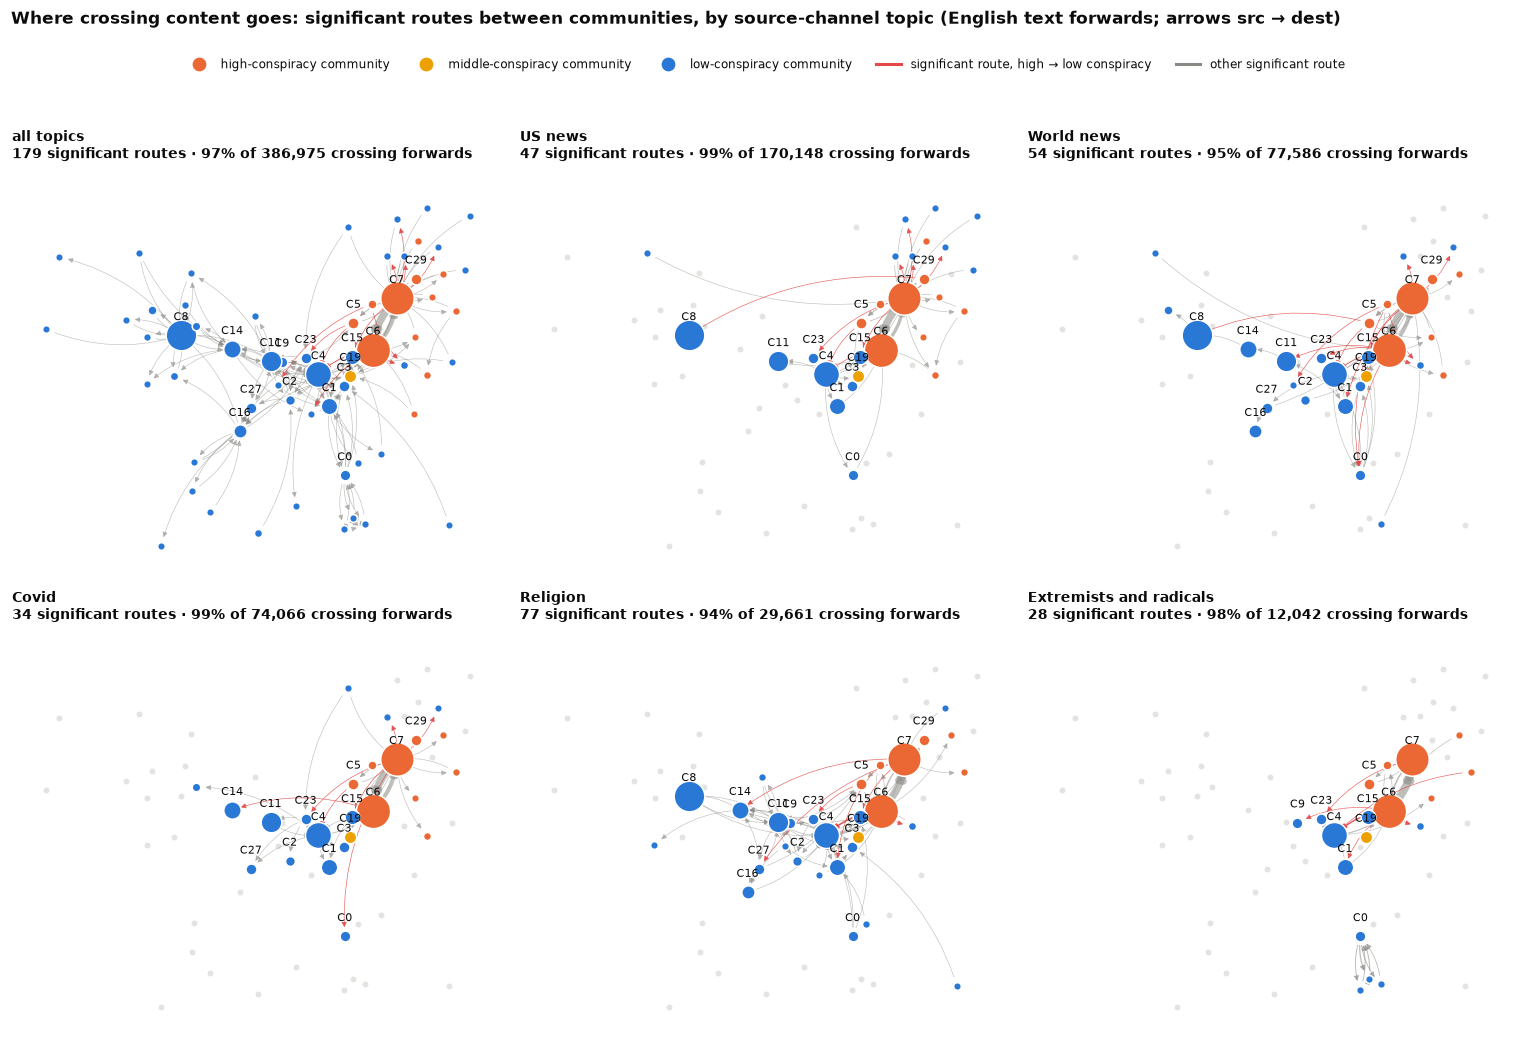

In [7]:
LEVEL_COLOR = {"high": plots.SERIES[1], "middle": plots.SERIES[3], "low": plots.SERIES[0]}
HL_COLOR = plots.SERIES[7]

nodes = sorted(set().union(*[set(R[t].src_id[R[t].significant]) | set(R[t].dest_id[R[t].significant]) for t in panel_topics]))
idx = {c: i for i, c in enumerate(nodes)}
ref = R["all topics"][R["all topics"].significant]
lay_g = ig.Graph(n=len(nodes), edges=[(idx[a], idx[b]) for a, b in zip(ref.src_id, ref.dest_id)])
random.seed(cfg.SEED)
pos = np.array(lay_g.layout_fruchterman_reingold(weights=np.log1p(ref.weight.to_numpy()).tolist(), niter=2000).coords)
pos = (pos - pos.min(axis=0)) / (pos.max(axis=0) - pos.min(axis=0))

def draw(ax, t):
    r = R[t]; s = r[r.significant]
    ax.scatter(pos[:, 0], pos[:, 1], s=8, color="#e4e3df", zorder=1)
    wmax = s.share_of_topic_crossing.max()
    for a, b, w, la, lb in zip(s.src_id, s.dest_id, s.share_of_topic_crossing, s.src_level, s.dst_level):
        is_hl = la == "high" and lb == "low"
        ax.annotate("", xy=pos[idx[b]], xytext=pos[idx[a]], zorder=2 if not is_hl else 3,
                    arrowprops=dict(arrowstyle="-|>", lw=0.4 + 4.5 * w / wmax, mutation_scale=7,
                                    color=HL_COLOR if is_hl else "#8a8984", alpha=0.9 if is_hl else 0.55,
                                    shrinkA=6, shrinkB=6, connectionstyle="arc3,rad=0.18"))
    used = sorted(set(s.src_id) | set(s.dest_id))
    for c in used:
        n = comm.loc[c, "english_channels"]
        ax.scatter(*pos[idx[c]], s=25 + 0.12 * n, color=LEVEL_COLOR[comm.loc[c, "level"]], edgecolor="white", lw=1, zorder=4)
        if n >= 100:
            ax.text(pos[idx[c]][0], pos[idx[c]][1] + 0.045, f"C{c}", ha="center", fontsize=7, color=plots.INK, zorder=5)
    ax.set_title(f"{t}\n{len(s)} significant routes · {summ.loc[t, 'on significant routes']:.0%} of "
                 f"{summ.loc[t, 'crossing forwards']:,.0f} crossing forwards", loc="left", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_xlim(-0.08, 1.08); ax.set_ylim(-0.08, 1.12)

fig, axes = plt.subplots(2, 3, figsize=(14, 9.5))
for ax, t in zip(axes.flat, panel_topics):
    draw(ax, t)
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", color=LEVEL_COLOR[l], markersize=8, label=f"{l}-conspiracy community")
           for l in ("high", "middle", "low")] + [
          Line2D([], [], color=HL_COLOR, lw=2, label="significant route, high → low conspiracy"),
          Line2D([], [], color="#8a8984", lw=2, label="other significant route")]
fig.legend(handles=handles, loc="upper center", ncol=5, fontsize=8, bbox_to_anchor=(0.5, 0.96))
fig.suptitle("Where crossing content goes: significant routes between communities, by source-channel topic "
             "(English text forwards; arrows src → dest)", x=0.01, y=0.995, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plots.savefig(fig, "03b_fig1_route_maps", OUT)
plt.show()

**Community key** for the figure (communities with ≥ 100 English channels that appear in any panel).

In [8]:
key = comm.loc[[c for c in nodes if comm.loc[c, "english_channels"] >= 100],
               ["label", "level", "english_channels", "channels"]].sort_values("english_channels", ascending=False)
key.style.format({"english_channels": "{:,}", "channels": "{:,}"})

,label,level,english_channels,channels
community,,,,
6,C6 · Religion · 35% consp.,high,"3,977","5,067"
7,C7 · US news · 67% consp.,high,"3,795","4,099"
8,C8 · Videogame modding · 1% consp.,low,"3,144","3,878"
4,C4 · Religion · 4% consp.,low,"2,225","6,386"
11,C11 · Religion · 1% consp.,low,"1,316","2,789"
14,C14 · Porn · 2% consp.,low,873,"1,623"
1,C1 · Religion · 3% consp.,low,761,"20,504"
15,C15 · Software · 5% consp.,low,557,"1,466"
16,C16 · Indian edu · 0% consp.,low,424,"1,351"


## 4 · Summary

In [9]:
a = summ.loc["all topics"]
print(f'''All topics: {a['significant routes']:.0f} significant routes (of {a['routes used']:.0f} used) carry {a['on significant routes']:.0%} of {a['crossing forwards']:,.0f} crossing forwards.
High → low conspiracy: {a['high → low (all routes)']:.1%} of crossing forwards in total, {a['high → low (significant routes)']:.1%} on significant routes.''')
for t in panel_topics[1:]:
    s = summ.loc[t]
    top = hl[hl.topic == t].head(2)
    via = "; ".join(f"{f.split(' · ')[0]} → {to.split(' · ')[0]} ({w:,} fwd, lift {l:.1f})"
                    for f, to, w, l in zip(top["from"], top["to"], top.weight, top.lift)) or "none significant"
    print(f"{t:>24}: {s['significant routes']:.0f} significant routes, {s['on significant routes']:.0%} of crossings on them; "
          f"high → low {s['high → low (all routes)']:.1%}; main high → low routes: {via}")

All topics: 179 significant routes (of 354 used) carry 97% of 386,975 crossing forwards.
High → low conspiracy: 2.6% of crossing forwards in total, 2.1% on significant routes.
                 US news: 47 significant routes, 99% of crossings on them; high → low 1.4%; main high → low routes: C7 → C15 (954 fwd, lift 1.5); C6 → C4 (733 fwd, lift 2.9)
              World news: 54 significant routes, 95% of crossings on them; high → low 2.2%; main high → low routes: C6 → C4 (975 fwd, lift 2.4); C7 → C15 (260 fwd, lift 1.3)
                   Covid: 34 significant routes, 99% of crossings on them; high → low 1.7%; main high → low routes: C7 → C15 (505 fwd, lift 1.4); C5 → C4 (138 fwd, lift 25.9)
                Religion: 77 significant routes, 94% of crossings on them; high → low 8.3%; main high → low routes: C6 → C4 (1,974 fwd, lift 1.3); C7 → C15 (63 fwd, lift 5.7)
 Extremists and radicals: 28 significant routes, 98% of crossings on them; high → low 7.4%; main high → low routes: C6 → C4 (8

## 5 · Illustration of proposal P1 (descriptive, not a result)

Proposal P1 (`DECISIONS.md`) would compare each topic's use of a route with crossing content in general:
ratio = (share of the topic's crossing forwards on the route) / (share of all crossing forwards on the
route). Below, the ratio for a few routes, **without uncertainty intervals**. It only shows the kind of
output P1 would give; P1 itself is not implemented.

In [10]:
ref_share = R["all topics"].set_index(["src_id", "dest_id"]).share_of_topic_crossing
ex = []
for t, x, y in [("Religion", 6, 4), ("Extremists and radicals", 6, 4), ("World news", 6, 4),
                ("Covid", 7, 15), ("US news", 7, 15), ("Covid", 7, 6)]:
    s = R[t].set_index(["src_id", "dest_id"]).share_of_topic_crossing.get((x, y), 0.0)
    ex.append({"topic": t, "route": f"C{x} → C{y}", "share of topic's crossings": s,
               "share of all crossings": ref_share[(x, y)], "ratio": s / ref_share[(x, y)]})
ex = pd.DataFrame(ex)
ex.style.format({"share of topic's crossings": "{:.2%}", "share of all crossings": "{:.2%}", "ratio": "{:.1f}"}).hide(axis="index")

topic,route,share of topic's crossings,share of all crossings,ratio
Religion,C6 → C4,6.66%,1.47%,4.5
Extremists and radicals,C6 → C4,6.91%,1.47%,4.7
World news,C6 → C4,1.26%,1.47%,0.9
Covid,C7 → C15,0.68%,0.47%,1.5
US news,C7 → C15,0.56%,0.47%,1.2
Covid,C7 → C6,61.76%,48.06%,1.3
